In [46]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from datasets import load_dataset

In [47]:
emotion_dataset=load_dataset("dair-ai/emotion","split")


In [48]:
emotion_dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

In [49]:
train_text=emotion_dataset["train"]["text"]
train_label=emotion_dataset["train"]["label"]


test_text=emotion_dataset["train"]["text"]
test_label=emotion_dataset["train"]["label"]

In [50]:
label_names=emotion_dataset["train"].features["label"].names

In [51]:
label_names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [52]:
df_train=pd.DataFrame(
    {
        'text':train_text,
        'label':[label_names[i] for i in train_label]
    }
)

df_test=pd.DataFrame(
    {
        'text':train_text,
        'label':[label_names[i] for i in train_label]
    }
)

In [53]:
label_names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [54]:
for i in train_label:
  print(label_names[i])

sadness
sadness
anger
love
anger
sadness
surprise
fear
joy
love
sadness
joy
anger
sadness
joy
joy
sadness
sadness
sadness
fear
anger
fear
joy
joy
anger
sadness
sadness
sadness
anger
joy
joy
fear
surprise
anger
joy
joy
joy
joy
anger
joy
joy
joy
joy
joy
sadness
sadness
joy
love
joy
anger
joy
sadness
anger
fear
joy
sadness
sadness
surprise
joy
joy
joy
love
fear
fear
surprise
anger
anger
sadness
love
joy
sadness
sadness
joy
sadness
sadness
sadness
joy
joy
joy
anger
sadness
anger
anger
anger
joy
joy
joy
joy
sadness
fear
love
anger
sadness
anger
love
sadness
joy
joy
sadness
anger
love
joy
joy
joy
sadness
joy
joy
joy
joy
sadness
joy
joy
love
sadness
sadness
joy
joy
sadness
joy
joy
fear
fear
fear
sadness
love
joy
joy
love
fear
surprise
joy
joy
joy
joy
anger
fear
joy
anger
love
anger
sadness
joy
sadness
anger
joy
surprise
sadness
anger
anger
sadness
joy
fear
joy
joy
fear
sadness
surprise
surprise
joy
anger
fear
anger
sadness
anger
sadness
fear
sadness
joy
surprise
fear
joy
anger
joy
anger
joy
f

In [55]:
df_test.head()

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [56]:
#EDA

In [57]:
df_train['label'].value_counts().index

Index(['joy', 'sadness', 'anger', 'fear', 'love', 'surprise'], dtype='object', name='label')

<Axes: xlabel='label', ylabel='count'>

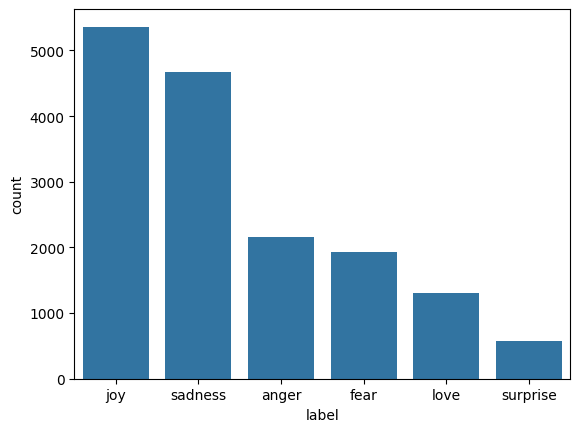

In [58]:
sns.countplot(x='label',data=df_train,order=df_train['label'].value_counts().index)

In [59]:
#data pre processing-using NLP

In [60]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_words=10000
max_len=50

tokenizer = Tokenizer(num_words=max_words, oov_token='unknown')
tokenizer.fit_on_texts(df_train['text'])

train_sequence = tokenizer.texts_to_sequences(df_train['text'])
test_sequence = tokenizer.texts_to_sequences(df_test['text'])

padded_train_sequence = pad_sequences(
    train_sequence,
    maxlen=max_len,
    padding='post',
    truncating='post'
)

padded_test_sequence = pad_sequences(
    test_sequence,
    maxlen=max_len,
    padding='post',
    truncating='post'
)

train_labels=np.array(train_label)
test_labels=np.array(test_label)
num_classes=len(np.unique(train_label))


print(f"vocabluray size:len{len(tokenizer.word_index)}")
print(f"max sentence length:{padded_train_sequence.shape[1]}")

vocabluray size:len15212
max sentence length:50


In [61]:
padded_train_sequence

array([[   2,  139,    3, ...,    0,    0,    0],
       [   2,   40,  101, ...,    0,    0,    0],
       [  17, 3060,    7, ...,    0,    0,    0],
       ...,
       [   2,    3,  327, ...,    0,    0,    0],
       [   2,    3,   14, ...,    0,    0,    0],
       [   2,   47,    7, ...,    0,    0,    0]], dtype=int32)

In [62]:
from sklearn.utils import class_weight
from sklearn.utils.class_weight import compute_class_weight

class_weight=class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_label),
    y=train_labels
)

class_weight_dict=dict(enumerate(class_weight))

In [71]:

from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)



In [72]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN ,Embedding,Dense,Dropout,LSTM,GRU

model=Sequential([
    Embedding(input_dim=max_words,output_dim=128,input_length=50),
    SimpleRNN(units=128,return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units=64),
    Dropout(0.5),
    Dense(units=num_classes,activation='softmax')
])

model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [77]:

import numpy as np

train_label = np.array(train_label)
test_label = np.array(test_label)

print(type(train_label))
print(train_label.shape)

print(type(test_label))
print(test_label.shape)


<class 'numpy.ndarray'>
(16000,)
<class 'numpy.ndarray'>
(16000,)


In [87]:

history = model.fit(
    padded_train_sequence,
    train_label,
    validation_data=(padded_test_sequence, test_label),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

rnn_loss, rnn_accuracy = model.evaluate(
    padded_test_sequence,
    test_label
)

print(f"RNN Loss: {rnn_loss}")
print(f"RNN Accuracy: {rnn_accuracy}")


Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 32ms/step - accuracy: 0.1494 - loss: 1.8052 - val_accuracy: 0.0362 - val_loss: 1.8265
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 19s 37ms/step - accuracy: 0.1443 - loss: 1.8000 - val_accuracy: 0.3327 - val_loss: 1.7658
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 18s 33ms/step - accuracy: 0.1402 - loss: 1.8002 - val_accuracy: 0.1331 - val_loss: 1.7809
500/500 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.0362 - loss: 1.8265
RNN Loss: 1.826456069946289
RNN Accuracy: 0.03618749976158142


In [86]:
LSTM_model=Sequential([
    Embedding(input_dim=max_words,output_dim=128,input_length=50),
    LSTM(units=128,return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=num_classes,activation='softmax')
])

model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

lstm_history = model.fit(
    padded_train_sequence,
    train_label,
    validation_data=(padded_test_sequence, test_label),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

LSTM_loss, LSTM_accuracy = model.evaluate(
    padded_test_sequence,
    test_label
)

print(f"LSTM Loss: {LSTM_loss}")
print(f"LSTM Accuracy: {LSTM_accuracy}")



Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 20s 37ms/step - accuracy: 0.1452 - loss: 1.8050 - val_accuracy: 0.1353 - val_loss: 1.8001
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 15s 31ms/step - accuracy: 0.1504 - loss: 1.8051 - val_accuracy: 0.0374 - val_loss: 1.8111
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 32ms/step - accuracy: 0.1388 - loss: 1.8032 - val_accuracy: 0.1214 - val_loss: 1.7937
500/500 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.1353 - loss: 1.8001
LSTM Loss: 1.8000547885894775
LSTM Accuracy: 0.1352500021457672


In [88]:
GRU_model=Sequential([
    Embedding(input_dim=max_words,output_dim=128,input_length=50),
    GRU(units=128,return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(units=num_classes,activation='softmax')
])

model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

GRU_history = model.fit(
    padded_train_sequence,
    train_label,
    validation_data=(padded_test_sequence, test_label),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

GRU_loss, GRU_accuracy = model.evaluate(
    padded_test_sequence,
    test_label
)

print(f"GRU Loss: {GRU_loss}")
print(f"GRU Accuracy: {GRU_accuracy}")


Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 19s 36ms/step - accuracy: 0.1402 - loss: 1.8000 - val_accuracy: 0.0826 - val_loss: 1.8063
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 18s 35ms/step - accuracy: 0.1504 - loss: 1.8031 - val_accuracy: 0.2919 - val_loss: 1.7716
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 21s 35ms/step - accuracy: 0.1458 - loss: 1.8010 - val_accuracy: 0.0362 - val_loss: 1.7942
500/500 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.0826 - loss: 1.8063
GRU Loss: 1.806270956993103
GRU Accuracy: 0.08256249874830246


In [92]:
result_df = pd.DataFrame({
    'model': ['SimpleRNN', 'LSTM', 'GRU'],
    'Test loss': [rnn_loss, LSTM_loss, GRU_loss],
    'Test_accuracy': [rnn_accuracy, LSTM_accuracy, GRU_accuracy]
}).sort_values(by='Test_accuracy', ascending=False)

result_df


,model,Test loss,Test_accuracy
1,LSTM,1.800055,0.135250
2,GRU,1.806271,0.082562
0,SimpleRNN,1.826456,0.036187


In [96]:
from tensorflow.keras.layers import Bidirectional

BiGRU=Sequential([
    Embedding(input_dim=max_words,output_dim=300,input_length=50),
    Bidirectional(GRU(128,return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(num_classes,activation='softmax')
])

BiGRU.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
BiGRU.summary()


Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_14 (Embedding)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_28 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_29 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [99]:
BiGRU_history = BiGRU.fit(
    padded_train_sequence,
    train_label,
    validation_data=(padded_test_sequence, test_label),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 128s 257ms/step - accuracy: 0.9818 - loss: 0.0568 - val_accuracy: 0.9886 - val_loss: 0.0318
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 132s 263ms/step - accuracy: 0.9809 - loss: 0.0544 - val_accuracy: 0.9842 - val_loss: 0.0514
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 136s 272ms/step - accuracy: 0.9816 - loss: 0.0527 - val_accuracy: 0.9918 - val_loss: 0.0239
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 111s 209ms/step - accuracy: 0.9866 - loss: 0.0409 - val_accuracy: 0.9941 - val_loss: 0.0195
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 141s 208ms/step - accuracy: 0.9902 - loss: 0.0336 - val_accuracy: 0.9924 - val_loss: 0.0272
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 112s 223ms/step - accuracy: 0.9898 - loss: 0.0320 - val_accuracy: 0.9942 - val_loss: 0.0174
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 105s 210ms/step - accuracy: 0.9909 - loss: 0.0290 - val_accuracy: 0.9939 - val_loss: 0.0184
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 139s 204ms/step - accuracy: 0.9926 -

In [105]:
BiGRU_loss, BiGRU_accuracy = BiGRU.evaluate(
    padded_test_sequence,
    test_label
)

print("BiGRU Loss:", BiGRU_loss)
print("BiGRU Accuracy:", BiGRU_accuracy)
print("BiGRU Accuracy (%):", BiGRU_accuracy * 100)

500/500 ━━━━━━━━━━━━━━━━━━━━ 19s 38ms/step - accuracy: 0.9960 - loss: 0.0120
BiGRU Loss: 0.011976922862231731
BiGRU Accuracy: 0.9959999918937683
BiGRU Accuracy (%): 99.59999918937683


In [106]:
print("Loss:", BiGRU.loss)
print("Optimizer:", BiGRU.optimizer)
print("Metrics:", BiGRU.metrics)

Loss: sparse_categorical_crossentropy
Optimizer: <keras.src.optimizers.adam.Adam object at 0x7cae0d8b5f90>
Metrics: [<Mean name=loss>, <CompileMetrics name=compile_metrics>]


500/500 ━━━━━━━━━━━━━━━━━━━━ 19s 37ms/step


<Axes: >

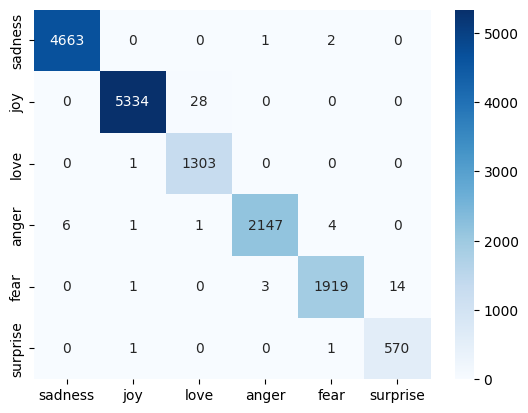

In [107]:
from sklearn.metrics import confusion_matrix
BiGRU_predictions=np.argmax(BiGRU.predict(padded_test_sequence),axis=1)
sns.heatmap(confusion_matrix(test_labels,BiGRU_predictions),annot=True,fmt='d',cmap='Blues',xticklabels=label_names,yticklabels=label_names)

In [108]:
sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences = pad_sequences(sample_sequences, maxlen=50, padding='post', truncating='post')

sample_predictions = np.argmax(BiGRU.predict(sample_padded_sequences), axis=1)

for i in range(len(sample_texts)):
  print(f'Text: {sample_texts[i]}\nPredicted Emotion: {label_names[sample_predictions[i]]}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 817ms/step
Text: I can't believe how happy I am right now, this is amazing!
Predicted Emotion: joy
Text: I feel so alone and hopeless today.
Predicted Emotion: sadness
Text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger
Text: I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear
Text: I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise


In [111]:
import os
import pickle

model_dir='Artifacts'
os.makedirs(model_dir,exist_ok=True)

#Save our BiGRU Model
BiGRU.save(os.path.join(model_dir, 'BiGRU_Modle.keras'))

#Save the tokenizer model
with open(os.path.join(model_dir, 'tokenizer.pkl'), 'wb') as file:
  pickle.dump(tokenizer, file)